In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!python --version

Python 3.12.13


In [ ]:
!pip show tensorflow

Name: tensorflow
Version: 2.20.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: /usr/local/lib/python3.12/dist-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, tensorboard, termcolor, typing_extensions, wrapt
Required-by: dopamine_rl, tensorflow-text, tf_keras, ydf_tf


In [1]:
!pip install alibi
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib

In [2]:
scaler_f_dir = '/content/drive/MyDrive/ml/XAI/scaler_f.pkl'
scaler_t_dir = '/content/drive/MyDrive/ml/XAI/scaler_t.pkl'
encoder_dir = '/content/drive/MyDrive/ml/XAI/vae_enc_smoteen.keras'
classifier_dir = '/content/drive/MyDrive/ml/XAI/vae_classifier_smoteen.keras'
labels_dir = '/content/drive/MyDrive/ml/n_datasets/y_test.npy'
data = '/content/drive/MyDrive/ml/XAI/test_features_sequences.csv'

In [3]:
scaler_f = joblib.load(scaler_f_dir)
scaler_t = joblib.load(scaler_t_dir)
enc = keras.models.load_model(encoder_dir)
classifier = keras.models.load_model(classifier_dir)
df = pd.read_csv(data)
y_test = np.load(labels_dir)
#df

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [4]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()

In [5]:
from keras import models
@tf.function
def sampling_reparameterization(distribution_params) -> tf.Tensor:
    mean, log_var = distribution_params
    epsilon = tf.random.normal(shape=tf.shape(mean), mean=0., stddev=1.)
    z = mean + tf.exp(log_var / 2) * epsilon
    return z

@tf.function
def binary_entropy(p, eps=1e-7) -> tf.Tensor:
    p = tf.clip_by_value(p, eps, 1. - eps)
    return -(p * tf.math.log(p) + (1 - p) * tf.math.log(1 - p))

class UQ_VAE(models.Model):
    def __init__(self, encoder_dir, classifier_dir):
        super(UQ_VAE, self).__init__()
        self.encoder = models.load_model(encoder_dir)
        self.classifier = models.load_model(classifier_dir)
        self.logits_classifier = models.Model(inputs=self.classifier.input, outputs=[self.classifier.layers[-1].output, self.classifier.layers[-2].output])

    @tf.function
    def _mc_forward_pass(self, x, S):
        if self.encoder is None or self.classifier is None:
            raise ValueError("Los modelos encoder y classifier no han sido cargados correctamente.")
        mean, log_var = self.encoder(x, training=True)  # (B, 128)
        mean = tf.expand_dims(mean, axis=1)        # (B, 1, 128)
        log_var = tf.expand_dims(log_var, axis=1)  # (B, 1, 128)
        # Repetimos S veces
        mean = tf.repeat(mean, repeats=S, axis=1)      # (B, S, 128)
        log_var = tf.repeat(log_var, repeats=S, axis=1)
        z = sampling_reparameterization((mean, log_var))  # (B, S, 128)
        B = tf.shape(z)[0]
        z_flat = tf.reshape(z, (-1, 128))  # (B*S, 128)

        p, logits = self.logits_classifier(z_flat, training=True)  # (B*S, 1)
        p = tf.reshape(p, (B, S))               # (B, S)
        logits = tf.reshape(logits, (B, S))     # (B, S)
        p_mean = tf.reduce_mean(p, axis=1)      # (B,)
        logits_mean = tf.reduce_mean(logits, axis=1)
        u_aleatoric = tf.reduce_mean(binary_entropy(p), axis=1)  # (B,)
        return p_mean, logits_mean, u_aleatoric

    def predict_with_uncertainty(self, dataset, T=20, S=20):
        all_p_mean = []
        all_logits_mean = []
        all_u_aleatoric = []
        for x_batch in dataset:
            batch_p = []
            batch_logit = []
            batch_u_a = []
            for _ in range(T):
                p_mean_t, logits_mean_t, u_a_t = self._mc_forward_pass(x_batch, S)
                batch_p.append(p_mean_t)
                batch_logit.append(logits_mean_t)
                batch_u_a.append(u_a_t)

            # Stack epistémico
            batch_p = tf.stack(batch_p, axis=0)        # (T, B)
            batch_logit = tf.stack(batch_logit, axis=0) # (T, B)
            batch_u_a = tf.stack(batch_u_a, axis=0)    # (T, B)

            u_aleatoric = tf.reduce_mean(batch_u_a, axis=0)  # (B,)
            logits_mean = tf.reduce_mean(batch_logit, axis=0)
            p_marginal = tf.reduce_mean(batch_p, axis=0)
            u_total = binary_entropy(p_marginal)
            u_epistemic = u_total - u_aleatoric

            all_p_mean.append(p_marginal)
            all_logits_mean.append(logits_mean)
            all_u_aleatoric.append((u_total, u_aleatoric, u_epistemic))

        return (
            tf.concat(all_p_mean, axis=0),
            tf.concat(all_logits_mean, axis=0),
            tuple(tf.concat(x, axis=0) for x in zip(*all_u_aleatoric))
        )

In [6]:
uq = UQ_VAE(encoder_dir, classifier_dir)

In [7]:
!pip install "transformers<5"
import transformers
from transformers import BertTokenizer, TFBertModel

In [8]:
model_name = "Rostlab/prot_bert"
tokenizer = BertTokenizer.from_pretrained(model_name, do_lower_case=False)
model = TFBertModel.from_pretrained(model_name, from_pt=True)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.predictions.decoder.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight', 'cls.seq_relationship.weight', 'cls.seq_relationship.bias', 'cls.predictions.bias', 'cls.predictions.trans

## Sequences selection based of uncertainty level

In [9]:
test = tf.data.Dataset.from_tensor_slices(
    (df.iloc[:,:1024].to_numpy().astype('float32'), df.iloc[:,1024:-1].to_numpy().astype('float32'))
).batch(64)

In [10]:
predictions, logits, uncertainties = uq.predict_with_uncertainty(test)

In [11]:
u_total = uncertainties[0].numpy()

In [12]:

positive_class_indices = np.where(y_test == 1)[0]
uncertainties_positive = u_total[positive_class_indices]

max_uncertainty_relative_idx = np.argmax(uncertainties_positive)
min_uncertainty_relative_idx = np.argmin(uncertainties_positive)
idx_highest_uncertainty_positive = positive_class_indices[max_uncertainty_relative_idx]
idx_lowest_uncertainty_positive = positive_class_indices[min_uncertainty_relative_idx]

print(f"Index of the sequence with highest uncertainty (positive class): {idx_highest_uncertainty_positive}")
print(f"Value of highest uncertainty: {u_total[idx_highest_uncertainty_positive]:.4f}")
print(f"Index of the sequence with lowest uncertainty (positive class): {idx_lowest_uncertainty_positive}")
print(f"Value of lowest uncertainty: {u_total[idx_lowest_uncertainty_positive]:.4f}")

Index of the sequence with highest uncertainty (positive class): 898
Value of highest uncertainty: 0.6745
Index of the sequence with lowest uncertainty (positive class): 344
Value of lowest uncertainty: 0.0000


## Integrated Gradients Implementación

In [13]:
mean_tf = tf.constant(scaler_t.mean_, dtype=tf.float32)
scale_tf = tf.constant(scaler_t.scale_, dtype=tf.float32)

#def standardize(x):
#    return (x - mean_tf) / scale_tf

def standardize(tensor):
    return (tensor - mean_tf) / (scale_tf)

In [14]:
df['processed_sequence'] = df['sequence'].apply(lambda s: " ".join(list(s)))

In [15]:
df_test = pd.read_csv('/content/drive/MyDrive/ml/Machine_Learning/datasets/test_descriptores.csv')
columns = list(df_test.columns[4:])

### Modelo para predicción

In [ ]:
def predict(
    seq: str,
    physico_chemical_features: np.ndarray,
    tokenizer,
    bert_model,
    encoder: tf.keras.Model,
    classifier: tf.keras.Model,
):
    encoded = tokenizer(
        seq.tolist(),
        return_tensors="tf",
        padding=True,
        truncation=True,
        max_length=512
    )
    physico_chemical_features = tf.convert_to_tensor(physico_chemical_features, dtype=tf.float32)
    outputs = model(encoded)
    cls_embeddings = outputs.last_hidden_state[:, 0, :]
    scaled_emb = standardize(cls_embeddings)
    mean, _ = encoder([scaled_emb, physico_chemical_features], training=False)
    pred = classifier(mean, training=False)
    return pred.numpy()


In [ ]:
df.iloc[0,-1]

'M S A W L D E I R W T A D G L V P V V A Q E A G T G Q V L M V A W M N R E A L A L T A A E G Y A V Y W S R S R G R L W R K G E E S G H R Q K V L E I R I D C D E D V V L L K V E Q A G G I A C H T G R H H C F Y R V L Q D G R W V T V E P V L K P P D S I Y G A'

In [ ]:
preds = []
for i in range(0, len(y_test), 32):
  end = len(y_test) if i + 32 > len(y_test) else i + 32
  preds.append(predict(
      df.iloc[i:end,-1],
      (df.iloc[i:end,1024:-2].to_numpy()).reshape((-1, 887)),
      tokenizer=tokenizer,
      bert_model=model,
      encoder=enc,
      classifier=classifier
  ))
preds = np.vstack(preds)

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
def plot_con_matrix(matrix, class_labels, title):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()
y_pred = preds

In [ ]:
y_pred = (y_pred >= 0.5).astype(int)

### Variante con alibi

In [16]:
import numpy as np
import tensorflow as tf
from alibi.explainers import IntegratedGradients

pad_token_id = tokenizer.pad_token_id
pad_embedding = model.bert.embeddings(tf.constant([[pad_token_id]]))[0, 0, :]
# Definir el Wrapper compatible con Alibi
class AlibiWrapper(tf.keras.Model):
    def __init__(self, bert, encoder, classifier, pad_embed_vector, standardize_f):
        super().__init__()
        self.bert_layer = bert.bert if hasattr(bert, 'bert') else bert
        self.encoder = encoder
        self.classifier = classifier
        self.pad_embed_vector = pad_embed_vector
        self.standardize_fn = standardize_f

    def call(self, inputs):
        inputs_embeds = inputs[0]
        descriptores = inputs[1]
        diferencia = tf.reduce_sum(tf.abs(inputs_embeds - self.pad_embed_vector), axis=-1)

        # Si la diferencia es casi 0, es un token de padding.
        # Creamos la máscara: 1 para texto real (diferencia > 0), 0 para padding.
        attention_mask = tf.cast(diferencia > 1e-6, tf.int32)
        bert_output = self.bert_layer(
            input_ids=None,
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            training=False
        )
        cls_emb = bert_output.last_hidden_state[:, 0, :]
        scaled = self.standardize_fn(cls_emb)
        mean, _ = self.encoder([scaled, descriptores], training=False)
        final_out = self.classifier(mean, training=False)
        return final_out

# Preparar instancias
wrapper = AlibiWrapper(model, enc, classifier, pad_embedding, standardize)
inputs_embeds_tensor = tf.keras.Input(shape=(512, 1024), dtype=tf.float32, name='inputs_embeds')
descriptors_tensor = tf.keras.Input(shape=(887,), dtype=tf.float32, name='descriptors')
outputs = wrapper([inputs_embeds_tensor, descriptors_tensor])
alibi_explainer_model = tf.keras.Model(
    inputs=[inputs_embeds_tensor, descriptors_tensor],
    outputs=outputs,
    name="AlibiExplainerModel"
)


# Preparar datos de la muestra de alta incertidumbre
seq_n = df.iloc[idx_highest_uncertainty_positive, -1]
if len(seq_n.split(' ')) > 512:
    seq_n = ' '.join(seq_n.split(' ')[:512])

feat_n = df.iloc[idx_highest_uncertainty_positive, 1024:-2].to_numpy().reshape(1, -1)

tok_n = tokenizer(seq_n, return_tensors='tf', padding='max_length', truncation=True, max_length=512)
mask_n = tf.cast(tok_n['attention_mask'], tf.float32)


transformer = model.bert if hasattr(model, 'bert') else model
emb_n = transformer.embeddings(tok_n['input_ids'])
feat_n_tf = tf.convert_to_tensor(feat_n, dtype=tf.float32)

"""
dummy_out = wrapper([emb_n, feat_n_tf])

wrapper.inputs = [
    tf.keras.Input(shape=(512, 1024), dtype=tf.float32, name="emb_input"),
    tf.keras.Input(shape=(887,), dtype=tf.float32, name="feat_input")
]
wrapper.outputs = [tf.keras.Input(shape=(1,), dtype=tf.float32, name="output")]
wrapper.output_shape = tuple(dummy_out.shape)
"""


# Baselines
base_emb = tf.zeros_like(emb_n)
base_feat = tf.zeros_like(feat_n_tf)

ig = IntegratedGradients(alibi_explainer_model, n_steps=50, method='gausslegendre', internal_batch_size=2)
explanation = ig.explain(
    [emb_n.numpy(), feat_n_tf.numpy()],
    baselines=[base_emb.numpy(), base_feat.numpy()],
    target=1
)

attr_token_level_alibi = np.sum(explanation.attributions[0], axis=-1).squeeze()
attr_descriptors_alibi = explanation.attributions[1].squeeze()


TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


In [17]:
alibi_explainer_model([emb_n.numpy(), feat_n_tf.numpy()]).numpy()

array([[2.1891377e-16]], dtype=float32)

In [18]:
attr_token_level = attr_token_level_alibi[:len(seq_n.split(' '))]
tokens = seq_n.split(' ')

In [19]:
sum(attr_token_level), sum(attr_descriptors_alibi)

(-0.0417097538642693, -0.0819252739465804)

In [20]:
from IPython.display import HTML
import numpy as np

def plot_attributions(tokens, attributions):
    """
    Plots the original sequence with token contributions highlighted using a color gradient.

    Args:
        :tokens (list): List of tokens (strings).
        :attributions (np.ndarray): Array of attribution scores for each token.
    """
    if len(tokens) != len(attributions):
        raise ValueError("Tokens and attributions must have the same length.")

    max_abs_attr = np.max(np.abs(attributions))
    html_output = "<div style='font-family: Arial, sans-serif; font-size: 1.1em; line-height: 1.6; padding: 10px; border: 1px solid #eee; border-radius: 5px; background-color: #ddd;'>"

    for token, attr in zip(tokens, attributions):
        if max_abs_attr == 0:
            alpha = 0
        else:
            # Scale attribution to [-1, 1]
            scaled_attr = attr / max_abs_attr
            alpha = abs(scaled_attr) # Opacity based on absolute value
            alpha -= alpha/9
            alpha += 0.05

        if attr > 0:
            # Green shades for positive contributions
            color_str = f"rgba(0, 255, 0, {alpha})" # Darker green
        elif attr < 0:
            # Red shades for negative contributions
            color_str = f"rgba(255, 0, 0, {alpha})" # Red
        else:
            # Transparent for zero contribution
            color_str = "rgba(255, 255, 255, 0)"

        html_output += f"<span style='background-color: {color_str}; padding: 3px 5px; color: #fff; margin: 0 1px; border-radius: 3px; display: inline-block; white-space: pre;'>{token}</span>"

    html_output += "</div>"
    return HTML(html_output)

In [21]:
plot_attributions(tokens, attr_token_level)

In [22]:
import matplotlib.pyplot as plt
import numpy as np

def plot_descriptor_waterfall(
    descriptor_names,
    attributions,
    base_value=0.5,
    top_k=15,
    min_range=0.05
):
    """
    Crea un gráfico estilo Waterfall (similar a SHAP) para las atribuciones de los descriptores.
    Ajusta automáticamente el eje X para evitar distorsiones cuando el cambio es muy pequeño.
    """
    descriptor_names = np.array(descriptor_names)
    attributions = np.array(attributions)

    # Calcular el valor final (predicción)
    total_attr_sum = np.sum(attributions)
    final_value = base_value + total_attr_sum

    # Ordenar por magnitud absoluta
    abs_order = np.argsort(np.abs(attributions))[::-1]

    # Seleccionar top k y agrupar el resto
    top_idx = abs_order[:top_k]
    other_idx = abs_order[top_k:]

    selected_names = list(descriptor_names[top_idx])
    selected_attr = list(attributions[top_idx])

    if len(other_idx) > 0:
        other_sum = np.sum(attributions[other_idx])
        selected_names.append(f"{len(other_idx)} other features")
        selected_attr.append(other_sum)

    # Invertir para que el más importante esté arriba
    selected_names = selected_names[::-1]
    selected_attr = selected_attr[::-1]

    # Calcular posiciones acumuladas
    cumulative = np.cumsum([base_value] + selected_attr)
    left = cumulative[:-1]
    right = cumulative[1:]

    plt.figure(figsize=(12, 1 + 0.5 * len(selected_names)))

    # Colores: Azul para negativo, Rojo para positivo (estilo SHAP)
    colors = ['#ff0051' if val > 0 else '#008bfb' for val in selected_attr]

    for i in range(len(selected_names)):
        plt.barh(i, right[i] - left[i], left=left[i], color=colors[i], height=0.6)

        # Añadir etiqueta de valor de contribución
        val_str = f"{selected_attr[i]:+.4f}"
        txt_x = right[i] if selected_attr[i] > 0 else left[i]
        plt.text(txt_x, i, val_str, va='center',
                 ha='left' if selected_attr[i] > 0 else 'right',
                 fontsize=10, fontweight='bold', color=colors[i])

    # Líneas guía de inicio y fin
    plt.axvline(base_value, color='gray', linestyle='--', alpha=0.5)
    plt.axvline(final_value, color='black', linestyle='-', alpha=0.3)

    plt.yticks(range(len(selected_names)), selected_names)
    plt.xlabel(f"Model Output (Base: {base_value:.3f} → Final: {final_value:.3f})")
    plt.title("Local Explanation: Descriptor Contributions (Waterfall Plot)")

    # Lógica para evitar distorsión por escala pequeña
    current_min = min(left.min(), right.min(), base_value, final_value)
    current_max = max(left.max(), right.max(), base_value, final_value)
    actual_range = current_max - current_min

    # Si el rango es menor al mínimo deseado, centramos el gráfico en ese rango mínimo
    if actual_range < min_range:
        center = (current_max + current_min) / 2
        plt.xlim(center - min_range/2, center + min_range/2)
    else:
        limit_margin = actual_range * 0.15
        plt.xlim(current_min - limit_margin, current_max + limit_margin)

    plt.grid(axis='x', linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

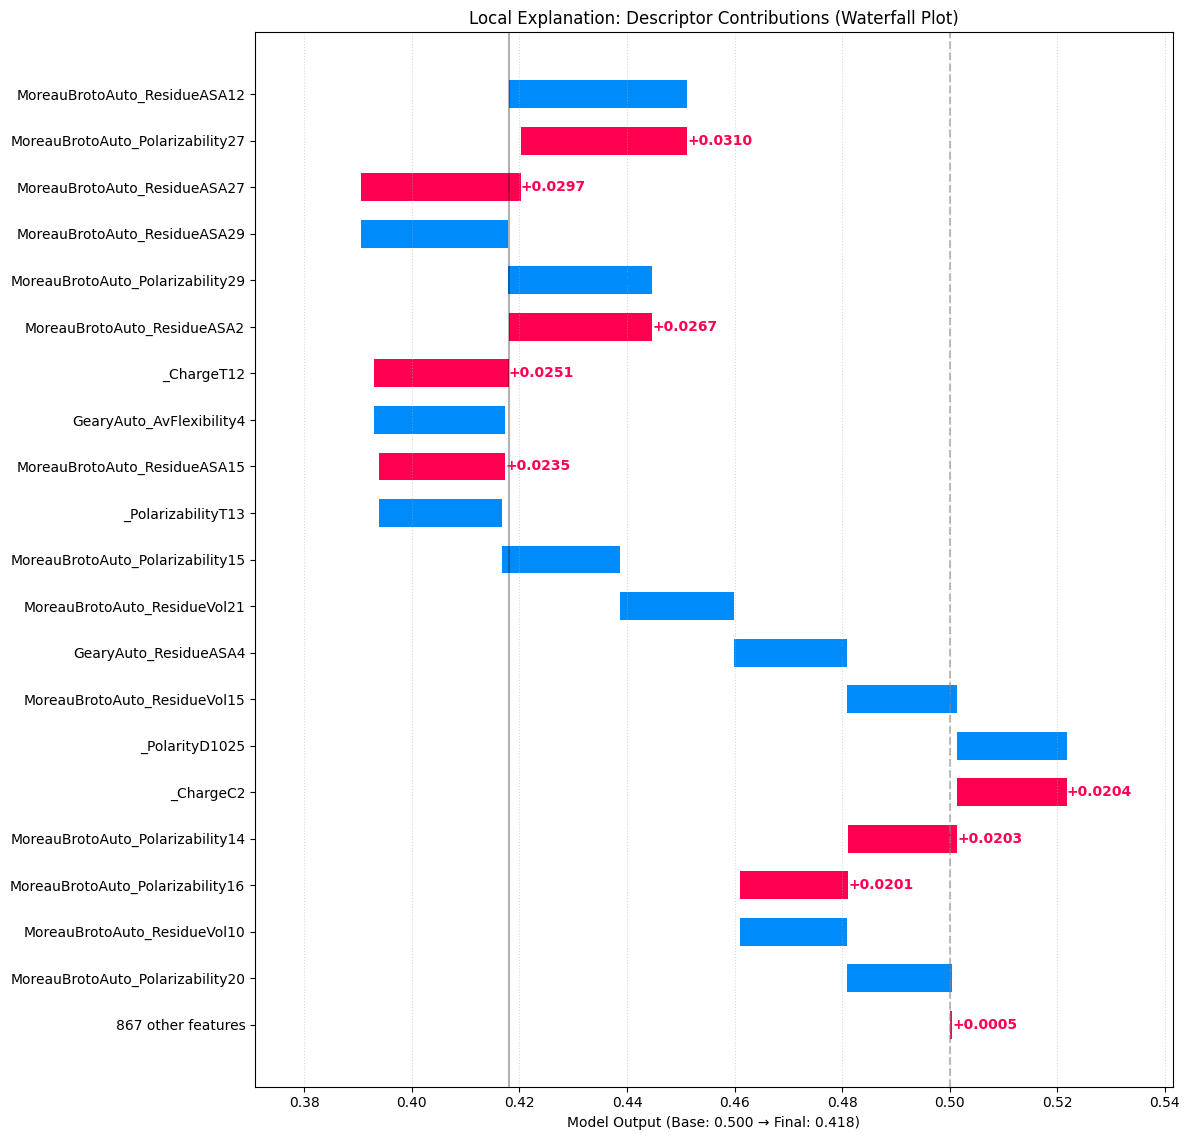

In [23]:
# Visualizar las atribuciones de descriptores usando el nuevo gráfico estilo SHAP waterfall
# Pasamos el base_value (el valor 'promedio' o baseline del modelo)
# y las atribuciones calculadas.

plot_descriptor_waterfall(
    descriptor_names=columns,
    attributions=attr_descriptors_alibi,
    base_value=0.5,
    top_k=20
)

#### lowest uncertainty

In [24]:
seq = df.iloc[idx_lowest_uncertainty_positive, -1]
if len(seq.split(' ')) > 512:
    seq = ' '.join(seq.split(' ')[:512])

feat = df.iloc[idx_lowest_uncertainty_positive, 1024:-2].to_numpy().reshape(1, -1)

tok = tokenizer(seq, return_tensors='tf', padding='max_length', truncation=True, max_length=512)
mask = tf.cast(tok['attention_mask'], tf.float32)

# Obtener embeddings base
transformer = model.bert if hasattr(model, 'bert') else model
emb = transformer.embeddings(tok['input_ids'])
feat_tf = tf.convert_to_tensor(feat, dtype=tf.float32)

In [25]:

explanation = ig.explain(
    [emb.numpy(), feat_tf.numpy()],
    baselines=[base_emb.numpy(), base_feat.numpy()],
    target=1
)

attr_token_level_alibi = np.sum(explanation.attributions[0], axis=-1).squeeze()
attr_descriptors_alibi = explanation.attributions[1].squeeze()
attr_token_level = attr_token_level_alibi[:len(seq.split(' '))]
tokens = seq.split(' ')

print(f"Sum of token attributions: {sum(attr_token_level):.4f}")
print(f"Sum of descriptor attributions: {sum(attr_descriptors_alibi):.4f}")
print(f"Total attribution: {sum(attr_token_level) + sum(attr_descriptors_alibi):.4f}")

Sum of token attributions: 3.5402
Sum of descriptor attributions: 0.9421
Total attribution: 4.4823


In [26]:
wrapper([emb.numpy(), feat_tf.numpy(), mask.numpy()]).numpy()

array([[0.9995715]], dtype=float32)

In [27]:
plot_attributions(tokens, attr_token_level)

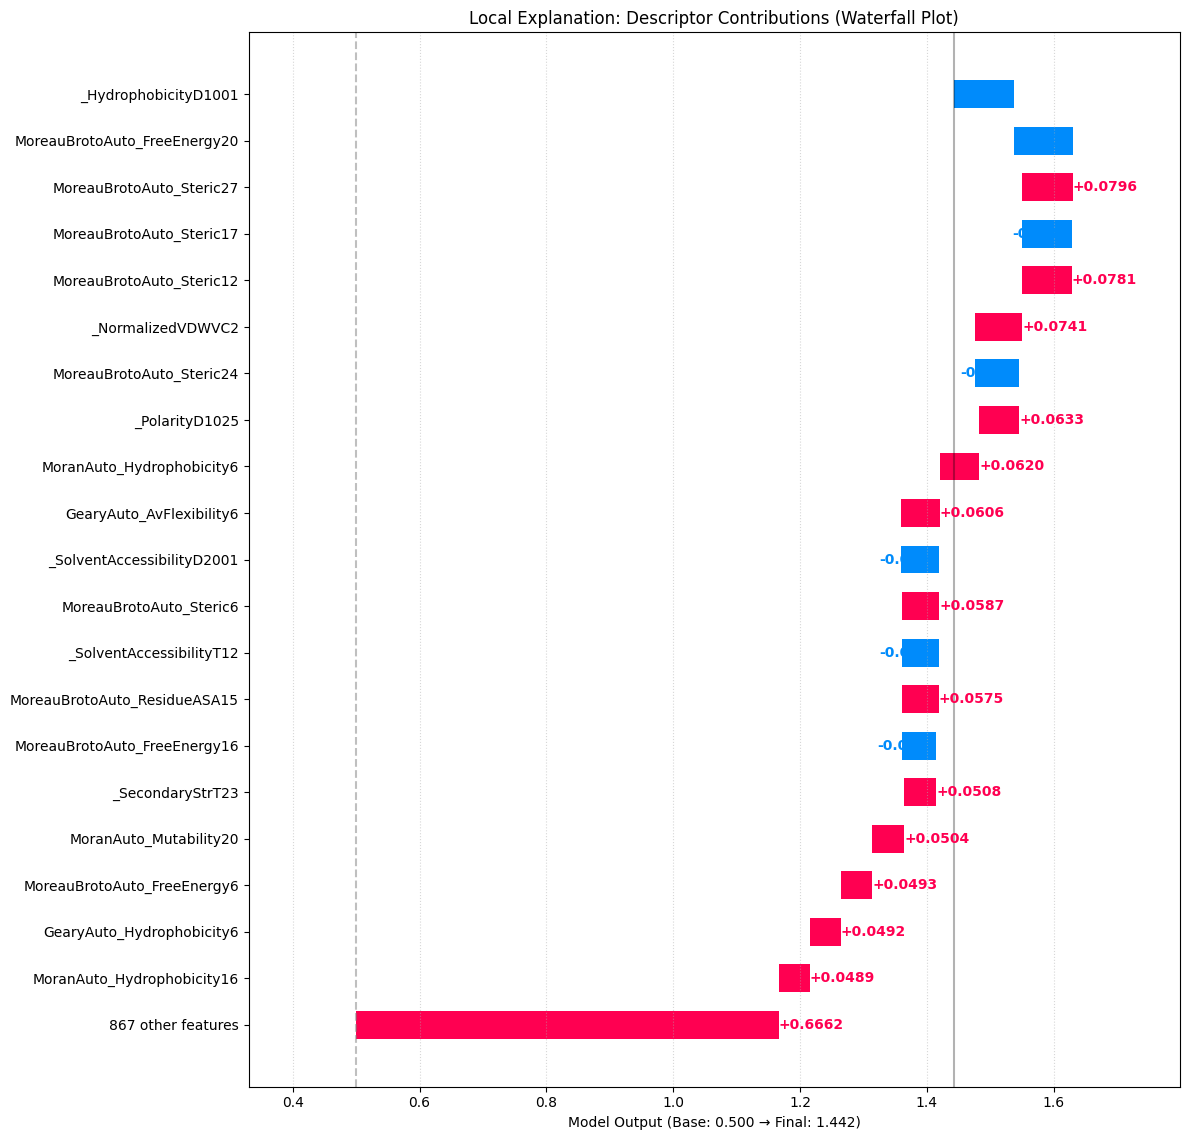

In [28]:
plot_descriptor_waterfall(
    descriptor_names=columns,
    attributions=attr_descriptors_alibi,
    base_value=0.5,
    top_k=20
)